In [4]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('../Data/temp_training.csv')
df.head()

/var/folders/22/3z4yr_bd5ds4d1g7ph9nprs80000gn/T/ipykernel_40092/3715099616.py:1: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../Data/temp_training.csv')


,Unnamed: 0.1,Unnamed: 0,id,stmt_date,HQ_city,legal_struct,ateco_sector,def_date,fs_year,asst_intang_fixed,...,profit,days_rec,ebitda,roa,roe,wc_net,margin_fin,cf_operations,default,data_type
0,0,17,520288,2011-12-31,28.0,SRL,14.0,NaN,2011,67537.0,...,-81288.0,NaN,6318.0,-3.81,-28.03,496258.0,-917029.0,-849.0,0,oot
1,1,18,520288,2008-12-31,28.0,SRL,14.0,NaN,2008,256438.0,...,-107382.0,NaN,46088.0,-2.76,NaN,97952.0,NaN,-3881.0,0,train
2,2,19,520288,2009-12-31,28.0,SRL,14.0,NaN,2009,194046.0,...,-77819.0,NaN,67611.0,-2.17,NaN,-210671.0,NaN,32618.0,0,train
3,4,22,520288,2007-12-31,28.0,SRL,14.0,NaN,2007,126603.0,...,36733.0,NaN,153060.0,6.20,52.43,-317007.0,-1184970.0,80039.0,0,train
4,5,23,520288,2010-12-31,28.0,SRL,14.0,NaN,2010,130973.0,...,-83593.0,NaN,3973.0,-4.08,-22.52,398756.0,-897381.0,-2104.0,0,test


In [6]:
mapping = pickle.load(open('../Files/column_mapping.pkl', 'rb'))

In [8]:
mapping['asset_cols']

['asst_intang_fixed',
 'asst_tang_fixed',
 'asst_fixed_fin',
 'asst_current',
 'AR',
 'cash_and_equiv',
 'asst_tot',
 'goodwill']

In [12]:
df_filt = df[mapping['asset_cols'] + ['default','data_type']]
df_filt

,asst_intang_fixed,asst_tang_fixed,asst_fixed_fin,asst_current,AR,cash_and_equiv,asst_tot,goodwill,default,data_type
0,67537.0,1137566.0,1908.0,733496.0,283013.0,2083.0,1946940.0,157436.0,0,oot
1,256438.0,1181416.0,860.0,622992.0,387653.0,5339.0,2077346.0,253845.0,0,train
2,194046.0,1152014.0,860.0,615252.0,388260.0,10492.0,1975874.0,238817.0,0,train
3,126603.0,1127807.0,620.0,484753.0,455224.0,14279.0,1769122.0,363557.0,0,train
4,130973.0,1136731.0,946.0,609723.0,280395.0,6528.0,1897604.0,164637.0,0,test
...,...,...,...,...,...,...,...,...,...,...
833343,1498628.0,248233.0,163477.0,5344865.0,5344243.0,622.0,7648851.0,7885956.0,0,oot
833344,2465065.0,343015.0,43477.0,2955420.0,2955276.0,144.0,6223862.0,5408857.0,0,train
833345,2375606.0,261775.0,28642.0,3079088.0,3044484.0,34605.0,6146110.0,4134865.0,0,train
833346,2973.0,1131586.0,264600.0,148612.0,118835.0,29777.0,1547771.0,-4795.0,0,test


In [14]:
df_filt = df_filt.sort_values(by='default')
df_filt

,asst_intang_fixed,asst_tang_fixed,asst_fixed_fin,asst_current,AR,cash_and_equiv,asst_tot,goodwill,default,data_type
0,67537.0,1137566.0,1908.0,733496.0,283013.0,2083.0,1946940.0,157436.0,0,oot
551094,290964.0,187651.0,0.0,5740454.0,4207530.0,27910.0,6232192.0,1687575.0,0,train
551095,1096126.0,568155.0,5000.0,11661633.0,7747969.0,210189.0,13362429.0,1404927.0,0,test
551096,811527.0,441066.0,109600.0,11727714.0,7124358.0,339738.0,13218027.0,2780354.0,0,oot
551097,622752.0,345725.0,509796.0,8779593.0,6091290.0,27730.0,10268839.0,1264613.0,0,train
...,...,...,...,...,...,...,...,...,...,...
779969,43332.0,1895410.0,0.0,2983289.0,1365722.0,982200.0,4924247.0,1032208.0,1,train
789143,57378.0,8907033.0,5995236.0,16449290.0,13587884.0,1774281.0,31591518.0,5387061.0,1,train
779971,0.0,32357.0,0.0,1972702.0,637564.0,19883.0,2035540.0,224410.0,1,train
779958,561.0,5879936.0,71.0,1274746.0,789.0,147132.0,7159108.0,-70220.0,1,train


In [26]:
df_filt['AR'].isna().sum()

np.int64(12)

In [25]:
temp = df_filt[['AR','default','data_type']]
temp['feat'] = np.log1p(temp['AR'])
# plt.hist(temp['feat'])

/opt/homebrew/Caskroom/miniconda/base/envs/nlp/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/homebrew/Caskroom/miniconda/base/envs/nlp/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/var/folders/22/3z4yr_bd5ds4d1g7ph9nprs80000gn/T/ipykernel_40092/1395079036.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp['feat'] = np.log1p(temp['AR'])


/opt/homebrew/Caskroom/miniconda/base/envs/nlp/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/homebrew/Caskroom/miniconda/base/envs/nlp/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


ValueError: supplied range of [-inf, 22.96945918694506] is not finite

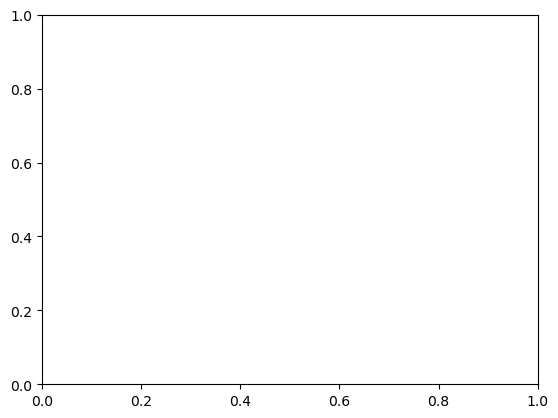

In [23]:
plt.hist(np.log1p(df_filt.query('default == 0')['AR']))
plt.hist(np.log1p(df_filt.query('default == 1')['AR']))